# Cross-session с moabb и вручную, обучение на 2 классах, тест на 4

1. Воспроизводится MOABB `CrossSessionEvaluation` для четырёх классов, `ACM+TS+SVM` и `FBCSP+SVM`
2. То же самое делается с функциями для обучения/тестирования, написанными вручную, результат сравниватеся с результатом moabb. Это нужно, чтобы дальше использовать эти функции для обучения на одних классах и тестирования на других
3. `ACM+TS+SVC` и `FBCSP+SVM` обучаются на `left_hand/right_hand` из `0train` и проверяются на всех классах `1test`.



In [1]:
import os
from pathlib import Path

DATA_ROOT = Path.home() / "mne_data"
DATA_ROOT.mkdir( parents=True, exist_ok=True )
os.environ.setdefault( "MNE_DATA", str( DATA_ROOT ) )
os.environ.setdefault( "MNE_DATASETS_BNCI_PATH", str( DATA_ROOT ) )
os.environ.setdefault( "MNE_DONTWRITE_HOME", "true" )

import mne
import numpy as np
import pandas as pd
import moabb
import pyriemann
import sklearn

from moabb.datasets import BNCI2014_001
from moabb.pipelines.features import AugmentedDataset
from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace
from sklearn.base import clone
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC

mne.set_log_level( "WARNING" )

/Users/liza/Projects/bci-motor-imagery/.venv/lib/python3.11/site-packages/optuna/integration/sklearn.py:14: FutureWarning: `optuna.integration.sklearn` has been deprecated in v4.9.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v4.9.0. Use `optuna_integration.sklearn` instead.
  optuna_warn(f"{msg} Use `optuna_integration.sklearn` instead.", FutureWarning)


In [2]:
print( "MOABB:", moabb.__version__ )
print( "MNE:", mne.__version__ )
print( "scikit-learn:", sklearn.__version__ )
print( "pyRiemann:", pyriemann.__version__ )

MOABB: 1.7.1
MNE: 1.12.1
scikit-learn: 1.9.0
pyRiemann: 0.12


In [3]:
dataset = BNCI2014_001( artifact_handling="ignore" )
ALL_EVENTS = dataset.event_id
ALL_CLASSES = tuple( ALL_EVENTS )
HAND_CLASSES = ( "left_hand", "right_hand" )
HAND_EVENTS = { label: ALL_EVENTS[ label ] for label in HAND_CLASSES }

ALL_DIRECTIONS = [ ( "0train", "1test" ), ( "1test", "0train" ) ]

In [4]:
import warnings
warnings.filterwarnings( "ignore", message=r"The `probability` parameter was deprecated.*", category=FutureWarning, module=r"sklearn\.svm\._base" )

## 1. Cross-session через MOABB
Параметры фиксированные, подбор не выполняется.

In [5]:
from moabb.evaluations import CrossSessionEvaluation
from moabb.paradigms import MotorImagery, FilterBankMotorImagery
from moabb.pipelines.utils import FilterBank
from pyriemann.spatialfilters import CSP
from sklearn.feature_selection import SelectKBest, mutual_info_classif

acm_ts_svc = make_pipeline(
    AugmentedDataset( order=3, lag=9 ),
    Covariances( estimator="cov" ),
    TangentSpace( metric="riemann" ),
    SVC( C=1, kernel="linear", probability=True )
)

class FilterBankMotorImageryFix( FilterBankMotorImagery ):
    def get_data( self, dataset, *args, process_pipelines=None, **kwargs ):
        return super().get_data( dataset, *args, process_pipelines=None, **kwargs )

fbcsp_svc = make_pipeline(
    FilterBank( make_pipeline( Covariances( estimator="oas" ), CSP( nfilter=8 ) ) ), 
    SelectKBest( mutual_info_classif, k=10 ), 
    SVC( C=1, kernel="linear", probability=True )
)

MOABB_RESULTS_PATH = Path( "moabb_cross" )
MOABB_RESULTS_PATH.mkdir( parents=True, exist_ok=True )
moabb_params = { "datasets": [ dataset ], "random_state": 42, "n_jobs": 1, "hdf5_path": str( MOABB_RESULTS_PATH ), "overwrite": False }

moabb_acm = CrossSessionEvaluation( paradigm=MotorImagery( n_classes=4 ), **moabb_params ).process( { "ACM+TS+SVM": acm_ts_svc } )
moabb_fbcsp = CrossSessionEvaluation( paradigm=FilterBankMotorImageryFix( n_classes=4 ), **moabb_params ).process( { "FBCSP+SVM": fbcsp_svc } )
moabb_cross = pd.concat( [ moabb_acm, moabb_fbcsp ], ignore_index=True )
display( moabb_cross.groupby( "pipeline" )[ "score" ].agg( [ "mean", "std", "count" ] ) )


Choosing from all possible events
/Users/liza/Projects/bci-motor-imagery/.venv/lib/python3.11/site-packages/moabb/analysis/results.py:189: H5pyDeprecationWarning: Creating a dataset without passing data or dtype is deprecated. Pass an explicit dtype. Using dtype='f4' will keep the current default behaviour.
  dset.create_dataset(
Choosing from all possible events
/Users/liza/Projects/bci-motor-imagery/.venv/lib/python3.11/site-packages/moabb/analysis/results.py:189: H5pyDeprecationWarning: Creating a dataset without passing data or dtype is deprecated. Pass an explicit dtype. Using dtype='f4' will keep the current default behaviour.
  dset.create_dataset(


,mean,std,count
pipeline,,,
ACM+TS+SVM,0.677469,0.131335,18
FBCSP+SVM,0.599537,0.130659,18


In [6]:
# функция для сравнения с полученными в moabb результатами
def compare_with_moabb( manual_results, pipeline ):
    manual = manual_results[ [ "subject", "session", "score" ] ].copy()
    reference = moabb_cross.query( "pipeline == @pipeline" )[ [ "subject", "session", "score" ] ].copy()
    comparison = manual.merge( reference, on=[ "subject", "session" ], suffixes=( "_manual", "_MOABB" ), validate="one_to_one" )
    summary = pd.DataFrame( { 
        "manual": comparison[ "score_manual" ].agg( [ "mean", "std", "count" ] ), 
        "MOABB": comparison[ "score_MOABB" ].agg( [ "mean", "std", "count" ] ) 
        } ).T
    return summary, comparison

## 2. Cross-session по 4 классам вручную



In [7]:
def prepare_session( runs, event_id, fmin=8, fmax=32 ):
    X, y = [], []
    code_to_label = { code: label for label, code in event_id.items() }

    for run in sorted( runs, key=int ):
        raw = runs[ run ].copy().filter( fmin, fmax, method="iir", picks="data", verbose=False )
        events = mne.find_events( raw, stim_channel="STI", shortest_event=1, verbose=False )
        epochs = mne.Epochs( raw, events, event_id, tmin=2, tmax=6, baseline=None, picks="eeg", proj=False, event_repeated="drop",  verbose=False )
        X.append( epochs.get_data() * dataset.unit_factor )
        y.extend( code_to_label[ code ] for code in epochs.events[ :, 2 ] )

    return np.concatenate( X ), np.array( y )

def train( session, model ):
    X_train, y_train = session
    return  clone( model ).fit( X_train, y_train )

def predict( session, model ):
    X_test, _ = session
    return model.predict( X_test )

def evaluate( prepared, model, subject, directions, known_classes ):
    rows, predictions = [], []

    for train_session, test_session in directions:
        fitted_model = train( prepared[ train_session ], model )
        y_test = prepared[ test_session ][ 1 ]
        y_pred = predict( prepared[ test_session ], fitted_model )
        
        platt_confidence = fitted_model.predict_proba( prepared[ test_session ][ 0 ] ).max( axis=1 )
        
        svm = fitted_model[ -1 ]
        if len( svm.classes_ ) == 2:
            decision = fitted_model.decision_function( prepared[ test_session ][ 0 ] )
            distance_to_hyperplane = np.abs( decision ) / np.linalg.norm( svm.coef_ )
        else:
            distance_to_hyperplane = np.full( len( y_test ), np.nan )

        known = np.isin( y_test, known_classes )
        unknown = ~known
        info = { 
            "subject": str( subject ), 
            "train_session": train_session, 
            "session": test_session }

        rows.append( {
            **info,
            "n_train": len( prepared[ train_session ][ 1 ] ),
            "n_test": len( y_test ),
            "n_unknown": int( ( ~known ).sum() ),
            "score": accuracy_score( y_test, y_pred ),
            "known_score": accuracy_score( y_test[ known ], y_pred[ known ] ),
        } )

        predictions.append( pd.DataFrame( {
            **info,
            "true_label": y_test,
            "predicted_label": y_pred,
            "is_known": known,
            "distance_to_hyperplane": distance_to_hyperplane,
            "platt_confidence": platt_confidence
        } ) )
    return rows, predictions

### 2.1 ACM_TS_SVM

In [8]:
all_rows, all_predictions = [], []

for subject in dataset.subject_list:
    raw_sessions = dataset.get_data( subjects=[ subject ], n_jobs=1 )[ subject ]
    prepared = { session: prepare_session( runs, ALL_EVENTS ) for session, runs in raw_sessions.items() }
    rows, predictions = evaluate( prepared, acm_ts_svc, subject, ALL_DIRECTIONS, ALL_CLASSES )
    all_rows.extend( rows )
    all_predictions.extend( predictions )
    score = np.mean( [ row[ "score" ] for row in rows ] )
    print( f"Subject {subject}: mean score {score}" )

results_all = pd.DataFrame( all_rows )
predictions_all = pd.concat( all_predictions, ignore_index=True )

Subject 1: mean score 0.828125
Subject 2: mean score 0.5868055555555556
Subject 3: mean score 0.8159722222222222
Subject 4: mean score 0.6180555555555556
Subject 5: mean score 0.4479166666666667
Subject 6: mean score 0.5677083333333333
Subject 7: mean score 0.7361111111111112
Subject 8: mean score 0.7847222222222222
Subject 9: mean score 0.7118055555555556


In [9]:
summary_acm, comparison_acm = compare_with_moabb( results_all, "ACM+TS+SVM" )
display( summary_acm )
print( "Max difference:", ( comparison_acm[ "score_manual" ] - comparison_acm[ "score_MOABB" ] ).abs().max() )
print( "All results close:", np.allclose( comparison_acm[ "score_manual" ], comparison_acm[ "score_MOABB" ] ) )

,mean,std,count
manual,0.677469,0.131335,18.0
MOABB,0.677469,0.131335,18.0


Max difference: 2.6490953208835322e-08
All results close: True


### 2.2 FBCSP+SVM

In [10]:
BANDS = [ ( 8, 12 ), ( 12, 16 ), ( 16, 20 ), ( 20, 24 ), ( 24, 28 ), ( 28, 32 ) ]

def prepare_filterbank( runs, event_id ):
    data = [ prepare_session( runs, event_id, fmin, fmax ) for fmin, fmax in BANDS ]
    return np.stack( [ X for X, _ in data ], axis=-1 ), data[ 0 ][ 1 ]


In [11]:
all_rows_fb, all_predictions_fb = [], []
hands_rows_fb, hands_predictions_fb = [], []

for subject in dataset.subject_list:
    raw_sessions = dataset.get_data( subjects=[ subject ], n_jobs=1 )[ subject ]
    prepared_all = { session: prepare_filterbank( runs, ALL_EVENTS ) for session, runs in raw_sessions.items() }

    rows, predictions = evaluate( prepared_all, fbcsp_svc, subject, ALL_DIRECTIONS, ALL_CLASSES )
    all_rows_fb.extend( rows )
    all_predictions_fb.extend( predictions )
    score = np.mean( [ row[ "score" ] for row in rows ] )
    print( f"Subject {subject}: mean score {score}" )

results_all_fb = pd.DataFrame( all_rows_fb )
predictions_all_fb = pd.concat( all_predictions_fb, ignore_index=True )

Subject 1: mean score 0.7638888888888888
Subject 2: mean score 0.4652777777777778
Subject 3: mean score 0.7552083333333333
Subject 4: mean score 0.5381944444444444
Subject 5: mean score 0.4670138888888889
Subject 6: mean score 0.43229166666666663
Subject 7: mean score 0.6440972222222222
Subject 8: mean score 0.703125
Subject 9: mean score 0.6267361111111112


In [12]:
summary_fbcsp, comparison_fbcsp = compare_with_moabb( results_all_fb, "FBCSP+SVM" )
display( summary_fbcsp )

print( "Max difference:", ( comparison_fbcsp[ "score_manual" ] - comparison_fbcsp[ "score_MOABB" ] ).abs().max() )
print( "All results close:", np.allclose( comparison_fbcsp[ "score_manual" ], comparison_fbcsp[ "score_MOABB" ] ) )

,mean,std,count
manual,0.599537,0.130659,18.0
MOABB,0.599537,0.130659,18.0


Max difference: 2.6490953208835322e-08
All results close: True


## 3. Обучаем на двух классах, проверяем на всех

Обучение: `0train` только `left_hand/right_hand`.  
Тест: `1test` все классы.


In [13]:
HANDS_DIRECTIONS = [ ( "0train", "1test" ) ]

### 3.1 ACM+TS+SVM

In [14]:

hands_rows, hands_predictions = [], []

for subject in dataset.subject_list:
    raw_sessions = dataset.get_data( subjects=[ subject ], n_jobs=1 )[ subject ]
    prepared = { 
        "0train": prepare_session( raw_sessions[ "0train" ], HAND_EVENTS ), 
        "1test": prepare_session( raw_sessions[ "1test" ], ALL_EVENTS ) }
    rows, predictions = evaluate( prepared, acm_ts_svc, subject, HANDS_DIRECTIONS, HAND_CLASSES )
    hands_rows.extend( rows )
    hands_predictions.extend( predictions )
    print( f"Subject {subject}: score {rows[0][ 'score' ]}, known score {rows[0][ 'known_score' ]}" )
    

results_hands = pd.DataFrame( hands_rows )
predictions_hands = pd.concat( hands_predictions, ignore_index=True )

Subject 1: score 0.4479166666666667, known score 0.8958333333333334
Subject 2: score 0.3125, known score 0.625
Subject 3: score 0.4791666666666667, known score 0.9583333333333334
Subject 4: score 0.3576388888888889, known score 0.7152777777777778
Subject 5: score 0.3611111111111111, known score 0.7222222222222222
Subject 6: score 0.3472222222222222, known score 0.6944444444444444
Subject 7: score 0.34375, known score 0.6875
Subject 8: score 0.4895833333333333, known score 0.9791666666666666
Subject 9: score 0.4166666666666667, known score 0.8333333333333334


In [15]:
display( results_hands[ [ "score", "known_score" ] ].agg( [ "mean", "std", "count" ] ) )

,score,known_score
mean,0.395062,0.790123
std,0.064768,0.129537
count,9.000000,9.000000


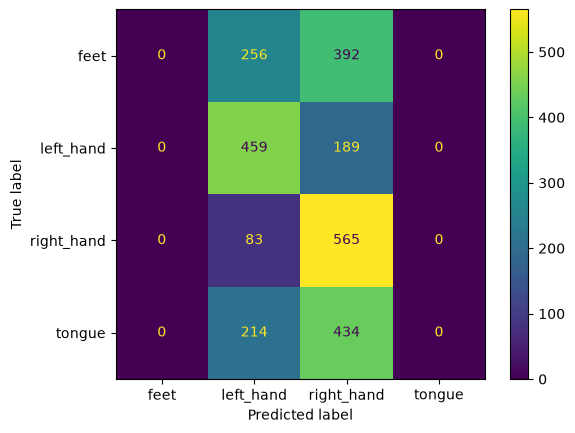

In [16]:

ConfusionMatrixDisplay.from_predictions(
    predictions_hands["true_label"],
    predictions_hands["predicted_label"]
)

In [17]:
display( predictions_hands.groupby( "is_known" )[ [ "distance_to_hyperplane", "platt_confidence" ] ].agg( [ "mean", "std" ] ) )

distance_to_hyperplane           platt_confidence          
                           mean       std             mean       std
is_known                                                            
False                  0.305253  0.248192         0.788308  0.155369
True                   0.440267  0.368885         0.829534  0.157677

### 3.2 FBCSP+SVM

In [18]:
hands_rows_fb, hands_predictions_fb = [], []

for subject in dataset.subject_list:
    raw_sessions = dataset.get_data( subjects=[ subject ], n_jobs=1 )[ subject ]
    prepared_hands = { 
        "0train": prepare_filterbank( raw_sessions[ "0train" ], HAND_EVENTS ), 
        "1test": prepare_filterbank( raw_sessions[ "1test" ], ALL_EVENTS ) }
    rows, predictions = evaluate( prepared_hands, fbcsp_svc, subject, HANDS_DIRECTIONS, HAND_CLASSES )
    hands_rows_fb.extend( rows )
    hands_predictions_fb.extend( predictions )
    print( f"Subject {subject}: score {rows[0][ 'score' ]}, known score {rows[0][ 'known_score' ]}" )


results_hands_fb = pd.DataFrame( hands_rows_fb )
predictions_hands_fb = pd.concat( hands_predictions_fb, ignore_index=True )

Subject 1: score 0.4548611111111111, known score 0.9097222222222222
Subject 2: score 0.2638888888888889, known score 0.5277777777777778
Subject 3: score 0.4791666666666667, known score 0.9583333333333334
Subject 4: score 0.3472222222222222, known score 0.6944444444444444
Subject 5: score 0.3993055555555556, known score 0.7986111111111112
Subject 6: score 0.2743055555555556, known score 0.5486111111111112
Subject 7: score 0.3611111111111111, known score 0.7222222222222222
Subject 8: score 0.4722222222222222, known score 0.9444444444444444
Subject 9: score 0.4583333333333333, known score 0.9166666666666666


In [19]:
display( results_hands_fb[ [ "score", "known_score" ] ].agg( [ "mean", "std", "count" ] ) )

,score,known_score
mean,0.390046,0.780093
std,0.083388,0.166775
count,9.000000,9.000000


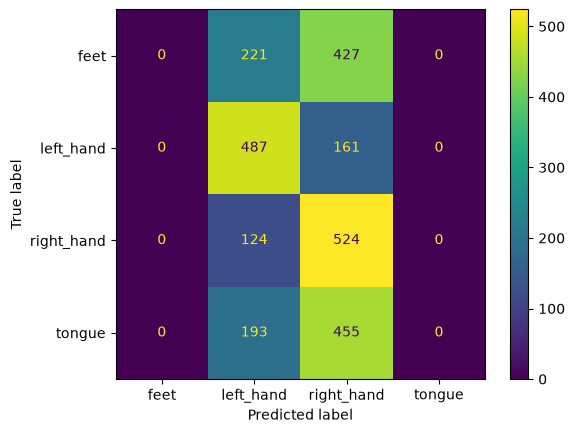

In [20]:

ConfusionMatrixDisplay.from_predictions(
    predictions_hands_fb["true_label"],
    predictions_hands_fb["predicted_label"]
)

In [21]:
display( predictions_hands_fb.groupby( "is_known" )[ [ "distance_to_hyperplane", "platt_confidence" ] ].agg( [ "mean", "std" ] ) )

distance_to_hyperplane           platt_confidence          
                           mean       std             mean       std
is_known                                                            
False                  0.432293  0.331865         0.820503  0.148749
True                   0.512948  0.409786         0.838897  0.150208